## TEST

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
TOY = ROOT / "toy"

sys.path.insert(0, str(TOY))

from train_add import train_add

print("Loaded train_add successfully.")

Loaded train_add successfully.


# Reproduction of Liu et al. Figure 4(b)

We investigate the critical training-data fraction for the toy addition task.

Original configuration:

- p = 10
- total unique samples = p(p+1)/2 = 55
- training sizes = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 54]
- seeds = [0, 1, 2]
- maximum training steps = 10,000
- high representation quality threshold: RQI > 0.95

The original paper reports a phase transition around r_c ≈ 0.4.

In [3]:
p = 10
all_num = p * (p + 1) // 2

print("Total samples:", all_num)

Total samples: 55


In [4]:
train_nums = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 54]

for n in train_nums:
    print(f"{n:2d}/55 = {n/55:.3f}")

 5/55 = 0.091
10/55 = 0.182
15/55 = 0.273
20/55 = 0.364
25/55 = 0.455
30/55 = 0.545
35/55 = 0.636
40/55 = 0.727
45/55 = 0.818
50/55 = 0.909
54/55 = 0.982


In [5]:
d = train_add(
    train_num=35,
    seed=0,
    steps=100,
    eff_steps=1,
    log_freq=20
)

batch size larger than the training set. We have set batch size=training size.
Using device: cpu
----------------------------------------
Task 1: Analyzing the dataset before training...
acc_ideal_test = 15/20=0.75
the degree of freedom (except translation/scaling) for the reprsentation is 0
dof=0 means the linear repr is the unique repr, while dof>0 means existence of other reprs
----------------------------------------
Task 2: Training with neural network...
step: 0  | loss: 0.98644251 
step: 20  | loss: 0.90655625 
step: 40  | loss: 0.89529890 
step: 60  | loss: 0.88707304 
step: 80  | loss: 0.88186747 
final train acc=0.1143, test acc=0.0000, RQI=0.0143
Steps to reach thresholds: train acc=99, test acc=99, RQI=99
----------------------------------------
Task 3: Training with effective loss...
step: 0  | loss: 312.83265796 
saving trajectories...


In [6]:
print(d.keys())

dict_keys(['all_num', 'train_num', 'test_num', 'train_ratio', 'test_ratio', 'ideal_test_acc', 'ideal_acc', 'pred_test_acc', 'pred_acc', 'dof', 'loss_train', 'loss_test', 'acc_train', 'acc_test', 'acc', 'repr_nn', 'repr_normalized_nn', 'rqi', 'iter_train', 'iter_test', 'iter_rqi', 'repr_eff', 'loss_eff', 'p', 'repr_dim', 'seed', 'steps', 'eff_steps', 'batch_size', 'init_scale_reprs', 'init_scale_nn', 'label_scale', 'eta_repr', 'eta_dec', 'width', 'weight_decay_repr', 'weight_decay_dec', 'threshold_train_acc', 'threshold_test_acc', 'threshold_rqi', 'threshold_P', 'loss_type'])


In [7]:
print("Training fraction:", d["train_ratio"])
print("Degrees of freedom:", d["dof"])
print("RQI threshold step:", d["iter_rqi"])

Training fraction: 0.6363636363636364
Degrees of freedom: 2
RQI threshold step: 99


## Replication

In [8]:
import time

start = time.perf_counter()

d_full = train_add(
    train_num=35,
    seed=0,
    steps=10_000,
    eff_steps=1,
    log_freq=1000
)

elapsed = time.perf_counter() - start

print("\n--- FULL EXPERIMENT RESULTS ---")
print(f"Training fraction: {d_full['train_ratio']:.4f}")
print(f"Degrees of freedom: {d_full['dof']}")
print(f"Steps to RQI threshold: {d_full['iter_rqi']}")
print(f"Final RQI: {d_full['rqi'][-1]:.4f}")
print(f"Final training accuracy: {d_full['acc_train'][-1]:.4f}")
print(f"Final validation accuracy: {d_full['acc_test'][-1]:.4f}")
print(f"Runtime: {elapsed:.1f} seconds")

batch size larger than the training set. We have set batch size=training size.
Using device: cpu
----------------------------------------
Task 1: Analyzing the dataset before training...
acc_ideal_test = 15/20=0.75
the degree of freedom (except translation/scaling) for the reprsentation is 0
dof=0 means the linear repr is the unique repr, while dof>0 means existence of other reprs
----------------------------------------
Task 2: Training with neural network...
step: 0  | loss: 0.98644251 
step: 1000  | loss: 0.46579626 
step: 2000  | loss: 0.18790966 
step: 3000  | loss: 0.07926615 
step: 4000  | loss: 0.02255960 
step: 5000  | loss: 0.00356040 
step: 6000  | loss: 0.00005665 
step: 7000  | loss: 0.00000018 
step: 8000  | loss: 0.00000021 
step: 9000  | loss: 0.00000007 
final train acc=1.0000, test acc=0.3500, RQI=0.5571
Steps to reach thresholds: train acc=2380, test acc=9999, RQI=9999
----------------------------------------
Task 3: Training with effective loss...
step: 0  | loss: 3

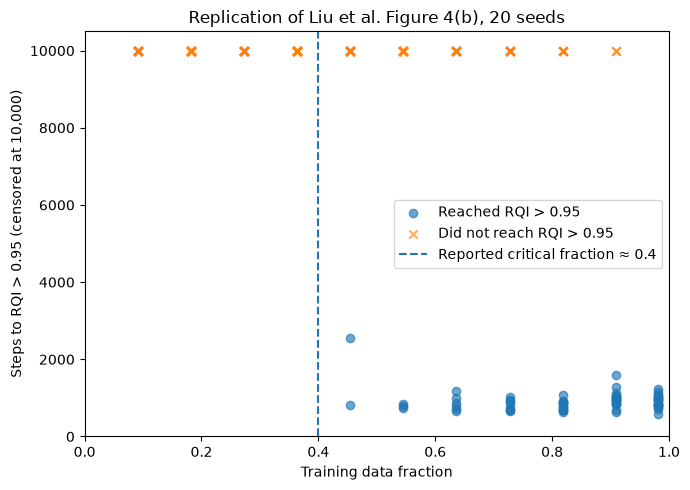

In [9]:
plt.figure(figsize=(7, 5))

success = df[df["reached_rqi"]]
failure = df[~df["reached_rqi"]]

plt.scatter(
    success["train_fraction"],
    success["iter_rqi"],
    alpha=0.65,
    label="Reached RQI > 0.95"
)

plt.scatter(
    failure["train_fraction"],
    failure["iter_rqi"],
    marker="x",
    alpha=0.65,
    label="Did not reach RQI > 0.95"
)

plt.axvline(
    0.4,
    linestyle="--",
    label="Reported critical fraction ≈ 0.4"
)

plt.xlabel("Training data fraction")
plt.ylabel("Steps to RQI > 0.95 (censored at 10,000)")
plt.title("Replication of Liu et al. Figure 4(b), 20 seeds")

plt.xlim(0, 1)
plt.ylim(0, 10500)

plt.legend()
plt.tight_layout()
plt.show()

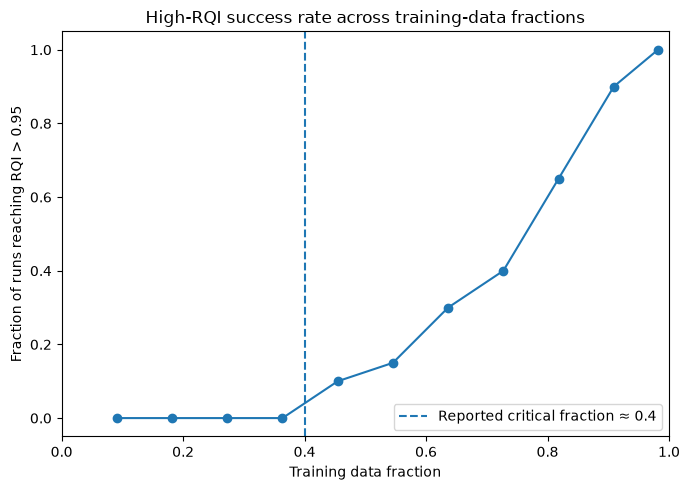

,train_num,train_fraction,successes,runs,success_rate
0,5,0.090909,0,20,0.00
1,10,0.181818,0,20,0.00
2,15,0.272727,0,20,0.00
3,20,0.363636,0,20,0.00
4,25,0.454545,2,20,0.10
5,30,0.545455,3,20,0.15
6,35,0.636364,6,20,0.30
7,40,0.727273,8,20,0.40
8,45,0.818182,13,20,0.65
9,50,0.909091,18,20,0.90


In [10]:
success_rate = (
    df.groupby(["train_num", "train_fraction"])["reached_rqi"]
      .agg(["sum", "count", "mean"])
      .reset_index()
      .rename(columns={
          "sum": "successes",
          "count": "runs",
          "mean": "success_rate"
      })
)

plt.figure(figsize=(7, 5))

plt.plot(
    success_rate["train_fraction"],
    success_rate["success_rate"],
    marker="o"
)

plt.axvline(
    0.4,
    linestyle="--",
    label="Reported critical fraction ≈ 0.4"
)

plt.xlabel("Training data fraction")
plt.ylabel("Fraction of runs reaching RQI > 0.95")
plt.xlim(0, 1)
plt.ylim(-0.05, 1.05)
plt.title("High-RQI success rate across training-data fractions")

plt.legend()
plt.tight_layout()
plt.show()

success_rate

In [11]:
from pathlib import Path

FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Save Figure 1: steps-to-threshold plot
plt.figure(figsize=(7, 5))

success = df[df["reached_rqi"]]
failure = df[~df["reached_rqi"]]

plt.scatter(
    success["train_fraction"],
    success["iter_rqi"],
    alpha=0.65,
    label="Reached RQI > 0.95"
)

plt.scatter(
    failure["train_fraction"],
    failure["iter_rqi"],
    marker="x",
    alpha=0.65,
    label="Did not reach RQI > 0.95"
)

plt.axvline(
    0.4,
    linestyle="--",
    label="Reported critical fraction ≈ 0.4"
)

plt.xlabel("Training data fraction")
plt.ylabel("Steps to RQI > 0.95 (censored at 10,000)")
plt.xlim(0, 1)
plt.ylim(0, 10500)
plt.title("Replication of Liu et al. Figure 4(b), 20 seeds")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIG_DIR / "fig4b_20seeds_steps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Save Figure 2: success-rate plot
plt.figure(figsize=(7, 5))

plt.plot(
    success_rate["train_fraction"],
    success_rate["success_rate"],
    marker="o"
)

plt.axvline(
    0.4,
    linestyle="--",
    label="Reported critical fraction ≈ 0.4"
)

plt.xlabel("Training data fraction")
plt.ylabel("Fraction of runs reaching RQI > 0.95")
plt.xlim(0, 1)
plt.ylim(-0.05, 1.05)
plt.title("High-RQI success rate across training-data fractions")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIG_DIR / "fig4b_20seeds_success_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Saved figures to:", FIG_DIR)

Saved figures to: results/figures


## Exstenstion

In [12]:
import pandas as pd

ext = pd.read_csv("results/fig4b_extension.csv")

summary = (
    ext.groupby("train_fraction")
    .agg(
        success_rate=("reached_rqi", "mean"),
        successes=("reached_rqi", "sum"),
        runs=("reached_rqi", "size"),
        mean_final_rqi=("final_rqi", "mean"),
        mean_dof=("dof", "mean"),
    )
    .reset_index()
)

summary

,train_fraction,success_rate,successes,runs,mean_final_rqi,mean_dof
0,0.327273,0.00,0,20,0.130714,4.2
1,0.363636,0.00,0,20,0.133571,3.4
2,0.400000,0.00,0,20,0.170714,2.8
3,0.436364,0.05,1,20,0.251429,2.3
4,0.472727,0.10,2,20,0.241429,2.1
5,0.509091,0.15,3,20,0.311429,2.0
6,0.545455,0.15,3,20,0.309286,2.0


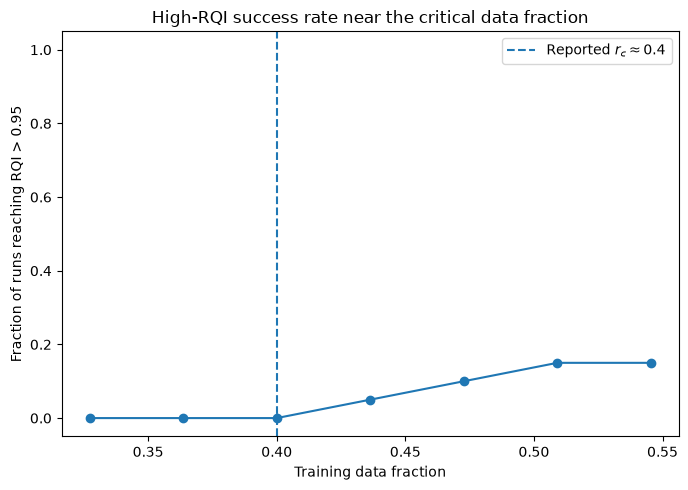

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    summary["train_fraction"],
    summary["success_rate"],
    marker="o"
)

plt.axvline(
    0.4,
    linestyle="--",
    label=r"Reported $r_c \approx 0.4$"
)

plt.xlabel("Training data fraction")
plt.ylabel("Fraction of runs reaching RQI > 0.95")
plt.ylim(-0.05, 1.05)
plt.title("High-RQI success rate near the critical data fraction")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
summary = (
    ext.groupby(["train_num", "train_fraction"])
    .agg(
        successes=("reached_rqi", "sum"),
        runs=("reached_rqi", "size"),
        success_rate=("reached_rqi", "mean"),
        mean_final_rqi=("final_rqi", "mean"),
    )
    .reset_index()
)
summary

,train_num,train_fraction,successes,runs,success_rate,mean_final_rqi
0,18,0.327273,0,20,0.00,0.130714
1,20,0.363636,0,20,0.00,0.133571
2,22,0.400000,0,20,0.00,0.170714
3,24,0.436364,1,20,0.05,0.251429
4,26,0.472727,2,20,0.10,0.241429
5,28,0.509091,3,20,0.15,0.311429
6,30,0.545455,3,20,0.15,0.309286


In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# Figure 1: Full 20-seed sweep, steps to high RQI
# ============================================================

df = pd.read_csv("results/fig4b_20seeds.csv")

success = df[df["reached_rqi"]]
failure = df[~df["reached_rqi"]]

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    success["train_fraction"],
    success["iter_rqi"],
    alpha=0.65,
    label="Reached RQI > 0.95"
)

ax.scatter(
    failure["train_fraction"],
    [10000] * len(failure),
    marker="x",
    alpha=0.65,
    label="Did not reach RQI > 0.95"
)

ax.axvline(
    0.4,
    linestyle="--",
    label=r"Reported $r_c \approx 0.4$"
)

ax.set_xlabel("Training data fraction")
ax.set_ylabel("Steps to RQI > 0.95 (censored at 10,000)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 10500)
ax.set_title("Replication of Liu et al. Figure 4(b), 20 seeds")
ax.legend()

fig.tight_layout()

steps_path = FIG_DIR / "fig4b_20seeds_steps.png"
fig.savefig(steps_path, dpi=300, bbox_inches="tight")
plt.close(fig)


# ============================================================
# Figure 2: Full 20-seed sweep, success rate
# ============================================================

summary_full = (
    df.groupby(["train_num", "train_fraction"])
      .agg(
          successes=("reached_rqi", "sum"),
          runs=("reached_rqi", "size"),
          success_rate=("reached_rqi", "mean"),
          mean_final_rqi=("final_rqi", "mean"),
      )
      .reset_index()
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    summary_full["train_fraction"],
    summary_full["success_rate"],
    marker="o"
)

ax.axvline(
    0.4,
    linestyle="--",
    label=r"Reported $r_c \approx 0.4$"
)

ax.set_xlabel("Training data fraction")
ax.set_ylabel("Fraction of runs reaching RQI > 0.95")
ax.set_xlim(0, 1)
ax.set_ylim(-0.05, 1.05)
ax.set_title("High-RQI success rate across training-data fractions")
ax.legend()

fig.tight_layout()

success_rate_path = FIG_DIR / "fig4b_20seeds_success_rate.png"
fig.savefig(success_rate_path, dpi=300, bbox_inches="tight")
plt.close(fig)


# ============================================================
# Figure 3: Dense extension near critical fraction
# ============================================================

ext = pd.read_csv("results/fig4b_extension.csv")

summary_ext = (
    ext.groupby(["train_num", "train_fraction"])
       .agg(
           successes=("reached_rqi", "sum"),
           runs=("reached_rqi", "size"),
           success_rate=("reached_rqi", "mean"),
           mean_final_rqi=("final_rqi", "mean"),
       )
       .reset_index()
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    summary_ext["train_fraction"],
    summary_ext["success_rate"],
    marker="o"
)

ax.axvline(
    0.4,
    linestyle="--",
    label=r"Reported $r_c \approx 0.4$"
)

ax.set_xlabel("Training data fraction")
ax.set_ylabel("Fraction of runs reaching RQI > 0.95")
ax.set_ylim(-0.05, 1.05)
ax.set_title("High-RQI success rate near the critical data fraction")
ax.legend()

fig.tight_layout()

extension_path = FIG_DIR / "fig4b_extension.png"
fig.savefig(extension_path, dpi=300, bbox_inches="tight")
plt.close(fig)


print("Saved figures:")
print(steps_path)
print(success_rate_path)
print(extension_path)

Saved figures:
results/figures/fig4b_20seeds_steps.png
results/figures/fig4b_20seeds_success_rate.png
results/figures/fig4b_extension.png
